# Deliverable — Data Preprocessing and Initial Model Development

## Predicting 30-Day Hospital Readmission in Diabetic Inpatients

**Team**

| Member | GitHub | Owns | Role |
|---|---|---|---|
| Omkar Pakki | [omkar1117](https://github.com/omkar1117) | Section 3 | Split design, pipeline, baseline models, tuning, threshold, interpretability |
| VenkataPhanisreeChinmayee Gorugonthu | [Chins-10](https://github.com/Chins-10) | Sections 1–2 | Problem framing, loading, cohort construction, feature engineering, EDA |
| Santosh Guntuka | [santoshguntuka](https://github.com/santoshguntuka) | Sections 4–7 | Fairness audit, ethics, deviations, summary, team process |

*Cross-review: Chinmayee → Omkar → Santosh → Chinmayee.*

**Repository:** [https://github.com/omkar1117/uc-ind-rp2-grp-5](https://github.com/omkar1117/uc-ind-rp2-grp-5)

**Colab:** [https://colab.research.google.com/drive/1eYXfmnfr8qVV2nsrU0fsjE2HV467Lqp9](https://colab.research.google.com/drive/1eYXfmnfr8qVV2nsrU0fsjE2HV467Lqp9)

**Dataset:** Clore, J., Cios, K., DeShazo, J., & Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999-2008* \[Dataset\]. UCI Machine Learning Repository. [doi.org/10.24432/C5230J](https://doi.org/10.24432/C5230J)

---
## 1. Introduction & Problem Framing
*Owner: Chinmayee*

**Stakeholder.** A hospital quality-operations team accountable under the CMS Hospital Readmissions Reduction Program, which withholds up to 3% of Medicare reimbursement for excess 30-day readmissions.

**Operational constraint.** Discharge-planning capacity is fixed. Follow-up calls, home-health referrals and medication reconciliation reach roughly the top 20% of discharges, not all of them. The team does not need a system that decides anything — it needs those limited slots allocated well. The deliverable is a **ranked worklist**, not an automated decision.

**Why that framing drives everything below:**

| Framing decision | Consequence |
|---|---|
| Output is a ranked list, not an action | Ranking quality (PR-AUC) is the headline metric |
| Positive class is a small minority | A do-nothing model scores high on accuracy, so accuracy is disqualified |
| A missed readmission costs more than an unnecessary call | Threshold is set by capacity, not left at 0.50 |
| Output informs clinician judgement | Model must be interpretable and auditable across groups |

**Formulation.** Binary classification: given an encounter record available at discharge, estimate P(readmission within 30 days). The raw label has three levels; `>30` is treated as negative because a readmission at 45 days falls outside both the CMS penalty window and the team's intervention window.

## Setup

In [1]:
import os

# download once; a re-run reuses the files already on disk
if not os.path.exists('diabetic_data.csv'):
    !wget -q "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip" -O diabetes.zip
    !unzip -oq diabetes.zip

!ls -lh diabetic_data.csv IDS_mapping.csv

-rw-r--r-- 1 root root 2.5K Nov 21 15:36 IDS_mapping.csv
-rw-r--r-- 1 root root  19M Nov 21 15:36 diabetic_data.csv


In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (RocCurveDisplay, PrecisionRecallDisplay,
                             average_precision_score, classification_report,
                             confusion_matrix, roc_auc_score)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 50)
RANDOM_STATE = 42

print(f'pandas {pd.__version__} | numpy {np.__version__}')

pandas 3.0.5 | numpy 2.5.3


---
## 2. Dataset Exploration & Preprocessing
*Owner: Chinmayee*

### 2.1 Load

Two arguments carry this cell.

`na_values=['?', '']` — this file encodes missing values as a literal question mark.

`keep_default_na=False` — stops pandas coercing the string `'None'` to a null. `'None'` is the most common value in `A1Cresult` and `max_glu_serum`, and it does **not** mean missing: it means the test was never ordered. That is a clinical finding, and it is the exact variable the source study was built around.

In [3]:
df = pd.read_csv('diabetic_data.csv', na_values=['?', ''], keep_default_na=False)

print(f'{df.shape[0]:,} encounters x {df.shape[1]} columns\n')
df.info()

101,766 encounters x 50 columns

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.020000e+00,1.450000e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.720000e+00,5.280000e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.750000e+00,4.060000e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.400000e+00,2.990000e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.310000e+01,1.967000e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.340000e+00,1.710000e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602000e+01,8.130000e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.700000e-01,1.270000e+00,0.0,0.0,0.0,0.000000e+00,42.0


In [5]:
# 'None' means the lab was never ordered - a finding, not a gap
labs = ['max_glu_serum', 'A1Cresult']
df[labs] = df[labs].replace('None', 'NotOrdered')

df['A1Cresult'].value_counts()

A1Cresult
NotOrdered    84748
>8             8216
Norm           4990
>7             3812
Name: count, dtype: int64

### 2.2 Target distribution

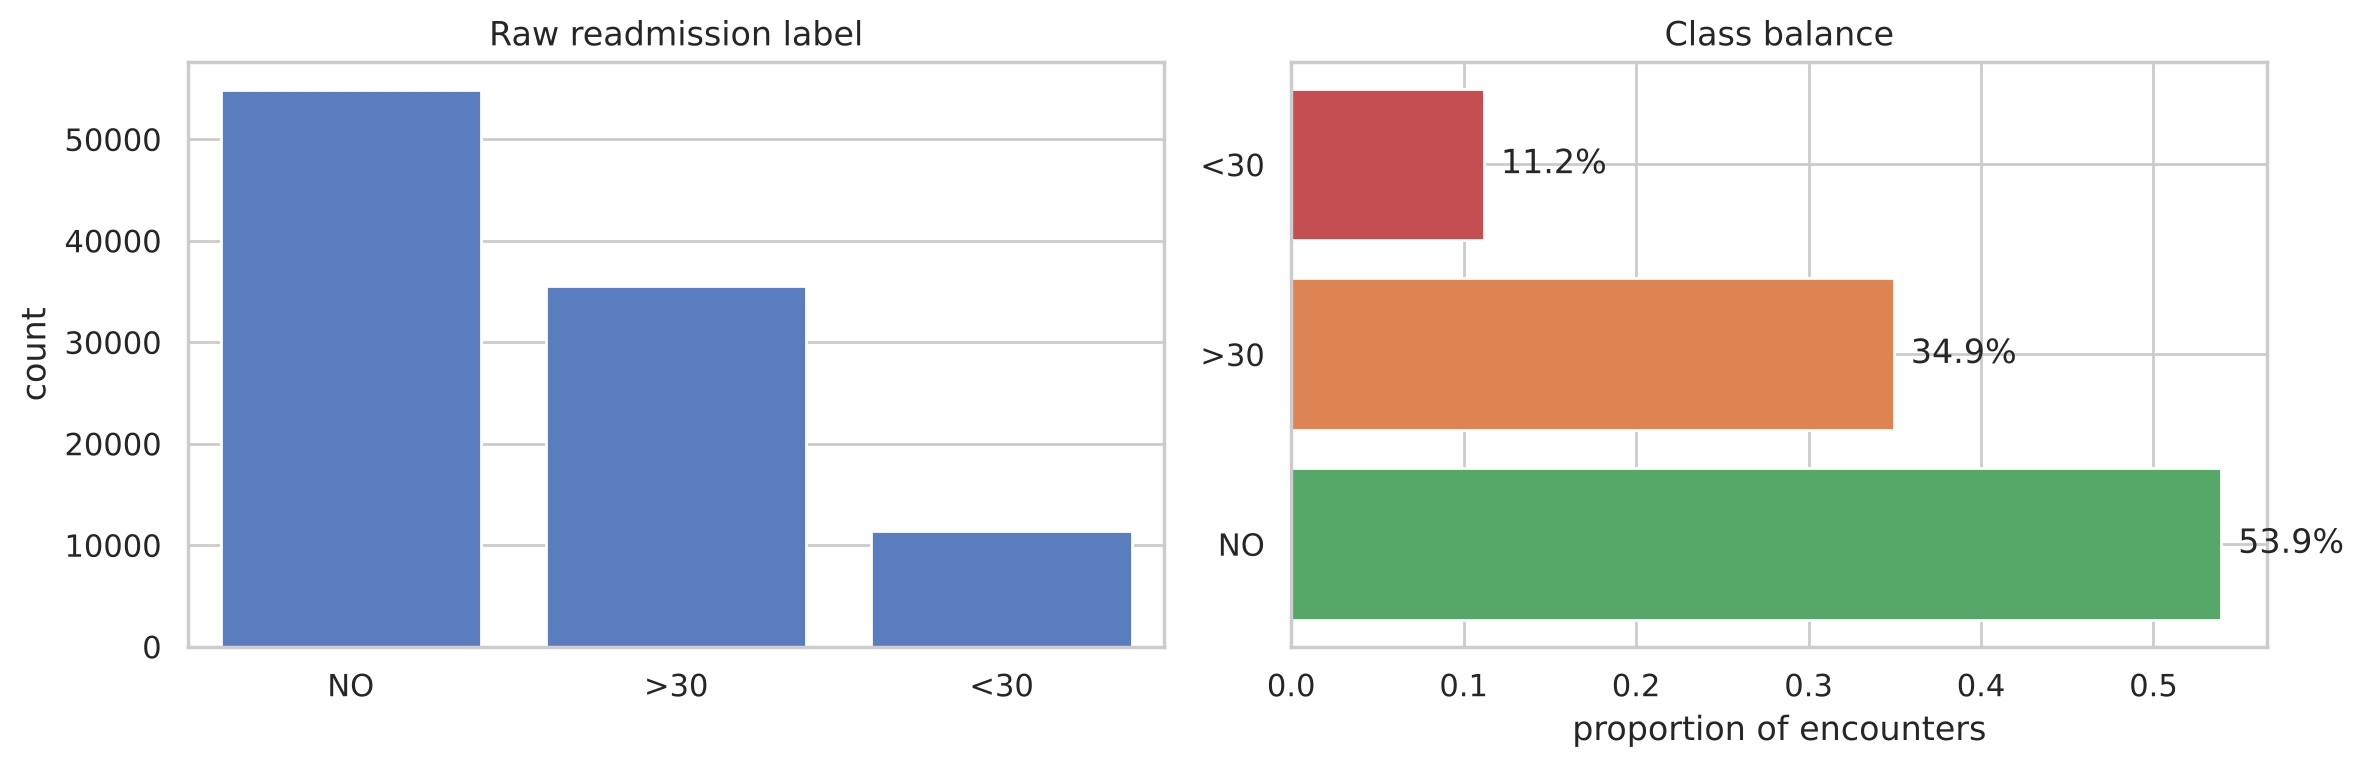

readmitted
NO     0.5391
>30    0.3493
<30    0.1116

RAW positive rate (all encounters): 0.1116
NOTE: this is the pre-cohort rate. Section 2.4 reports the rate the models actually see.


In [6]:
RAW_RATE = (df['readmitted'] == '<30').mean()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
order = ['NO', '>30', '<30']

sns.countplot(data=df, x='readmitted', order=order, ax=ax[0])
ax[0].set_title('Raw readmission label'); ax[0].set_xlabel('')

share = df['readmitted'].value_counts(normalize=True).reindex(order)
ax[1].barh(order, share.values, color=['#55A868', '#DD8452', '#C44E52'])
ax[1].set_title('Class balance'); ax[1].set_xlabel('proportion of encounters')
for i, v in enumerate(share.values):
    ax[1].text(v + .01, i, f'{v:.1%}', va='center')

plt.tight_layout(); plt.show()

print(df['readmitted'].value_counts(normalize=True).round(4).to_string())
print(f'\nRAW positive rate (all encounters): {RAW_RATE:.4f}')
print('NOTE: this is the pre-cohort rate. Section 2.4 reports the rate the models actually see.')

### 2.3 Missingness audit

We apply a single rule — drop any column more than 40% empty — and then report what that rule *actually* removed rather than assuming. Two columns clear the bar; `payer_code` sits just under it and is handled separately in Section 2.5.

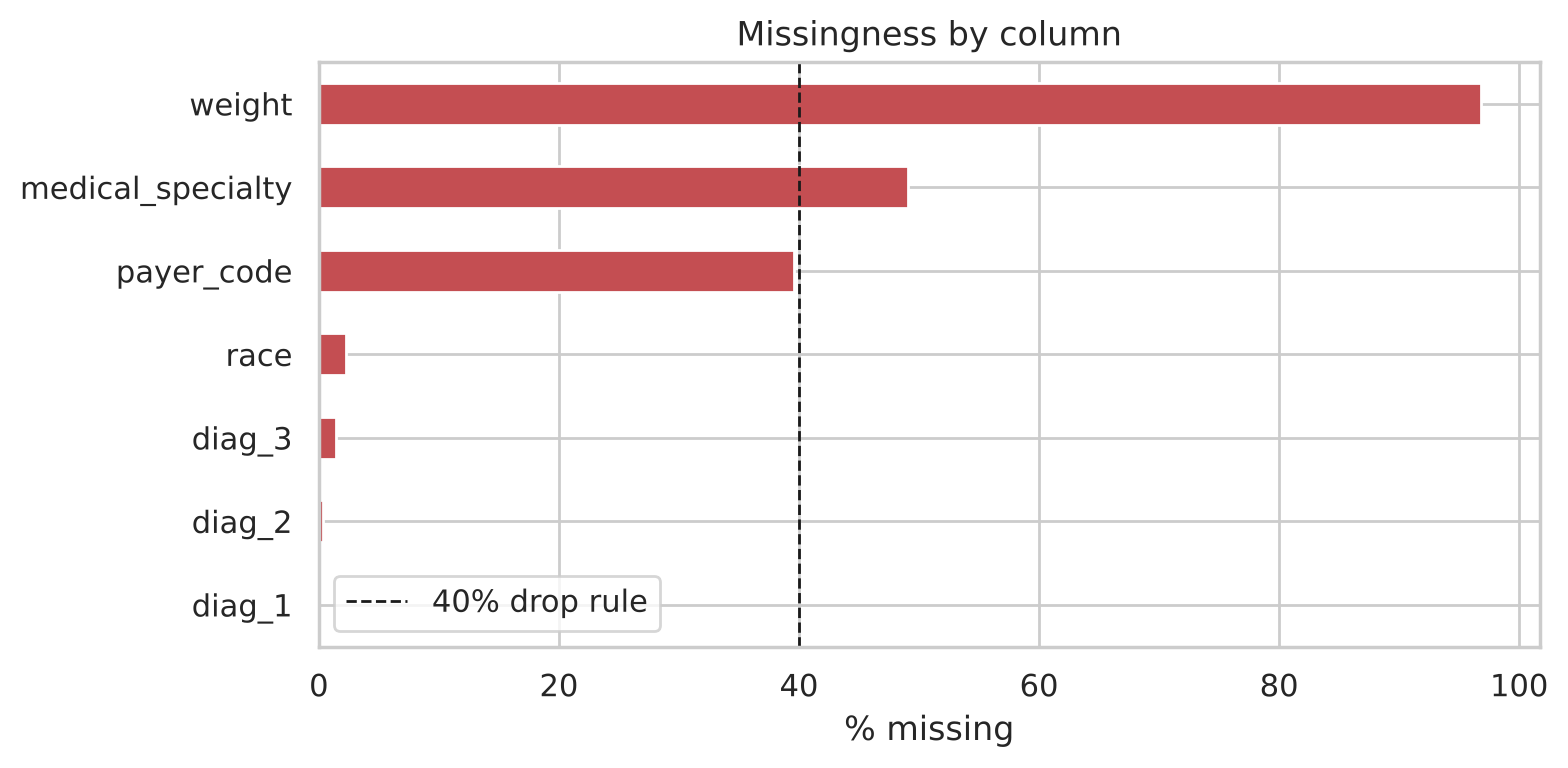

weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02


In [7]:
missing = df.isna().mean().sort_values(ascending=False)
missing_nonzero = missing[missing > 0]

fig, ax = plt.subplots(figsize=(8, 4))
missing_nonzero.mul(100).plot(kind='barh', ax=ax, color='#C44E52')
ax.axvline(40, ls='--', c='k', lw=1, label='40% drop rule')
ax.set_xlabel('% missing'); ax.set_title('Missingness by column')
ax.invert_yaxis(); ax.legend()
plt.tight_layout(); plt.show()

print(missing_nonzero.mul(100).round(2).to_string())

### 2.4 Cohort construction

Three filters, each encoding a clinical assumption.

1. **Expired and hospice discharges removed.** These patients could not be readmitted. Retaining them trains the model on an outcome that was never physically possible.
2. **Repeat encounters removed**, keeping each patient's first admission. Without this, the same individual appears in both train and test, so validation partly measures memorisation. This is the largest source of optimistic bias in published work on this dataset.
3. **`gender == 'Unknown/Invalid'` removed.** Note the comparison is against the **string**, not a null — this dataset stores the value literally, so `.notna()` would remove nothing. The cell prints both counts so the filter is visibly doing its job.

In [8]:
# the value is a STRING, not a null - verify before filtering on it
print(f"gender.isna()                  : {df['gender'].isna().sum()}")
print(f"gender == 'Unknown/Invalid'    : {(df['gender'] == 'Unknown/Invalid').sum()}")
print("-> .notna() would remove nothing; filter on the string instead.")

gender.isna()                  : 0
gender == 'Unknown/Invalid'    : 3
-> .notna() would remove nothing; filter on the string instead.


In [9]:
DEAD_OR_HOSPICE = [11, 13, 14, 19, 20, 21]
DROP_THRESHOLD = 0.40
audit = []

n0 = len(df)
df = df[~df['discharge_disposition_id'].isin(DEAD_OR_HOSPICE)]
audit.append(('Removed expired / hospice discharges', n0 - len(df), len(df)))

n0 = len(df)
df = df.sort_values('encounter_id').drop_duplicates('patient_nbr', keep='first')
audit.append(('Removed repeat encounters (keep first)', n0 - len(df), len(df)))

n0 = len(df)
df = df[df['gender'] != 'Unknown/Invalid']
audit.append(("Removed gender 'Unknown/Invalid'", n0 - len(df), len(df)))

drop_cols  = missing[missing > DROP_THRESHOLD].index.tolist()
borderline = missing[(missing > 0.30) & (missing <= DROP_THRESHOLD)].index.tolist()
df = df.drop(columns=drop_cols)
audit.append((f'Dropped >{DROP_THRESHOLD:.0%} empty columns', 0, len(df)))

display(pd.DataFrame(audit, columns=['Step', 'Rows removed', 'Rows remaining']))

print(f'Dropped  : {drop_cols}')
print(f'Retained : {borderline}  (below the {DROP_THRESHOLD:.0%} rule - see 2.5)')

,Step,Rows removed,Rows remaining
0,Removed expired / hospice discharges,2423,99343
1,Removed repeat encounters (keep first),29353,69990
2,Removed gender 'Unknown/Invalid',3,69987
3,Dropped >40% empty columns,0,69987


Dropped  : ['weight', 'medical_specialty']
Retained : ['payer_code']  (below the 40% rule - see 2.5)


#### The positive rate changes once the cohort is built

Deduplication removes later encounters, which are disproportionately the readmissions. The rate the models actually face is therefore **lower than the raw rate**, and every statement about class balance in this notebook refers to the cohort rate printed below.

In [10]:
df['readmit_30d'] = np.where(df['readmitted'] == '<30', 1, 0)
COHORT_RATE = df['readmit_30d'].mean()

print(f'Raw rate (all encounters)   : {RAW_RATE:.4f}')
print(f'Cohort rate (models see this): {COHORT_RATE:.4f}   '
      f'({df["readmit_30d"].sum():,} of {len(df):,})')
print(f'Shift                        : {(COHORT_RATE - RAW_RATE) * 100:+.2f} percentage points')
print()
print(f'=> Majority-class accuracy to beat : {1 - COHORT_RATE:.4f}')
print(f'=> Random-classifier PR-AUC        : {COHORT_RATE:.4f}')

Raw rate (all encounters)   : 0.1116
Cohort rate (models see this): 0.0898   (6,285 of 69,987)
Shift                        : -2.18 percentage points

=> Majority-class accuracy to beat : 0.9102
=> Random-classifier PR-AUC        : 0.0898


### 2.5 Feature engineering

**ICD-9 grouping — the highest-value transformation.** The three diagnosis columns each hold ~700 distinct codes. One-hot encoding them raw would add roughly 2,100 near-empty columns. We collapse them into the clinical groups used by Strack et al. (2014). The exact indicator count is computed below rather than asserted, because a `Missing` level appears whenever a diagnosis field is blank.

**`payer_code` is excluded from the feature set but retained for auditing.** It survived the 40% rule, but insurance status is a direct socioeconomic proxy. Using it as a predictor risks encoding ability-to-pay into a clinical triage score. Auditing *by* it — checking whether the model serves self-pay patients as well as privately insured ones — is the defensible use, and Section 4 does exactly that.

In [11]:
AGE_MID = {f'[{i}-{i+10})': i + 5 for i in range(0, 100, 10)}
df['age_mid'] = df['age'].map(AGE_MID)


def group_icd9(code):
    """Collapse ICD-9 codes into clinical groups (Strack et al., 2014)."""
    if pd.isna(code):
        return 'Missing'
    s = str(code).strip()
    if s.startswith(('E', 'V')):          # external causes / supplementary
        return 'Other'
    try:
        v = float(s)
    except ValueError:
        return 'Other'
    i = int(v)
    if 390 <= v <= 459 or i == 785:  return 'Circulatory'
    if 460 <= v <= 519 or i == 786:  return 'Respiratory'
    if 520 <= v <= 579 or i == 787:  return 'Digestive'
    if i == 250:                     return 'Diabetes'
    if 800 <= v <= 999:              return 'Injury'
    if 710 <= v <= 739:              return 'Musculoskeletal'
    if 580 <= v <= 629 or i == 788:  return 'Genitourinary'
    if 140 <= v <= 239:              return 'Neoplasms'
    return 'Other'


diag_levels = set()
for c in ['diag_1', 'diag_2', 'diag_3']:
    before = df[c].nunique()
    df[c + '_grp'] = df[c].apply(group_icd9)
    diag_levels |= set(df[c + '_grp'].unique())
    print(f'{c}: {before} raw codes -> {df[c + "_grp"].nunique()} groups')

print(f'\nDistinct levels across all three: {sorted(diag_levels)}')
print(f'Diagnosis indicators = 3 x {len(diag_levels)} = {3 * len(diag_levels)}')

diag_1: 694 raw codes -> 10 groups
diag_2: 723 raw codes -> 10 groups
diag_3: 756 raw codes -> 10 groups

Distinct levels across all three: ['Circulatory', 'Diabetes', 'Digestive', 'Genitourinary', 'Injury', 'Missing', 'Musculoskeletal', 'Neoplasms', 'Other', 'Respiratory']
Diagnosis indicators = 3 x 10 = 30


In [12]:
DISCHARGE_MAP = {1: 'Home', 6: 'Home_HealthSvc', 3: 'SNF', 2: 'Transfer_Hospital',
                 22: 'Transfer_Rehab', 5: 'Transfer_Other', 4: 'Transfer_Other'}
df['discharge_grp'] = df['discharge_disposition_id'].map(DISCHARGE_MAP).fillna('Other')

df['prior_visits'] = (df['number_outpatient'] + df['number_emergency']
                      + df['number_inpatient'])
df['meds_per_day'] = df['num_medications'] / df['time_in_hospital']

df[['discharge_grp', 'prior_visits', 'meds_per_day']].head()

,discharge_grp,prior_visits,meds_per_day
8,Home,0,2.153846
9,SNF,0,1.500000
4,Home,0,8.000000
10,Home,0,1.888889
5,Home,0,5.333333


#### Count-feature transforms (NumPy)

Some count columns are long-tailed and some are not, so we measure rather than assume. `skew()` scores each candidate — the five raw counts and the two features derived from them — and only those above a threshold of 1.0 are marked for transformation. Applying `log1p` to an already-symmetric column would introduce left skew rather than remove right skew. The decision table is printed so the selection is auditable.

- `np.percentile` with `np.clip` winsorizes at the 1st and 99th percentiles, so one extreme record cannot dominate a logistic coefficient.
- `np.log1p` compresses the remaining skew and is defined at zero, unlike `np.log`.
- `np.select` bins prior inpatient visits into utilisation tiers using fixed cut-points. The tier is kept *alongside* the continuous count deliberately: it gives the linear model a step function it cannot otherwise express, while the forest ignores the redundancy.

**Where the limits are learned.** The winsorizing limits are percentiles, which makes them fitted quantities like a scaler's mean. They are therefore learned inside the model pipeline (Section 3.2), from training rows only. The cell below applies the same two operations to the whole cohort purely to show their effect on skew; nothing it computes is passed to the models. Only the *choice of which columns to transform* is made here, from cohort-level skew.

Tree models are largely invariant to monotone transforms, so this matters for the logistic baseline rather than the forest — which is why it belongs in a comparison of the two.

In [13]:
CANDIDATES = ['num_lab_procedures', 'num_medications', 'number_outpatient',
              'number_emergency', 'number_inpatient', 'prior_visits', 'meds_per_day']
SKEW_THRESHOLD = 1.0


def winsor_log(x, lo, hi):
    """Clip to [lo, hi], then log1p. The same operation the pipeline applies in 3.2."""
    return np.log1p(np.clip(x, lo, hi))


skew_report = pd.DataFrame({
    'skew': df[CANDIDATES].skew().round(2),
    'median': df[CANDIDATES].median().round(2),
    'max': df[CANDIDATES].max().round(2),
})
skew_report['transform'] = np.where(skew_report['skew'] > SKEW_THRESHOLD,
                                    'winsorize + log1p', 'leave as is')

SKEWED = skew_report.index[skew_report['skew'] > SKEW_THRESHOLD].tolist()
UNTOUCHED = [c for c in CANDIDATES if c not in SKEWED]

# illustration only: effect of the transform on cohort-level skew (not used by the models)
skew_report['skew_after'] = np.nan
for col in SKEWED:
    lo, hi = np.percentile(df[col], [1, 99])
    skew_report.loc[col, 'skew_after'] = round(winsor_log(df[col], lo, hi).skew(), 2)

print(f'Skew test (threshold {SKEW_THRESHOLD}):')
print(skew_report.to_string())
print(f'\nto transform in the pipeline: {SKEWED}')
print(f'left as is                  : {UNTOUCHED}')

# fixed cut-points, so nothing is fitted here
df['utilization_tier'] = np.select(
    [df['number_inpatient'] >= 3, df['number_inpatient'] >= 1],
    ['high', 'medium'],
    default='low')

print('\nutilisation tiers from np.select:')
print(df.groupby('utilization_tier', observed=True)['readmit_30d']
        .agg(patients='size', readmit_rate='mean').round(3).to_string())

Skew test (threshold 1.0):
                     skew  median    max          transform  skew_after
num_lab_procedures  -0.22    44.0  132.0        leave as is         NaN
num_medications      1.43    14.0   81.0  winsorize + log1p       -0.32
number_outpatient    9.70     0.0   42.0  winsorize + log1p        2.78
number_emergency    21.23     0.0   42.0  winsorize + log1p        3.61
number_inpatient     5.59     0.0   12.0  winsorize + log1p        2.86
prior_visits         6.69     0.0   49.0  winsorize + log1p        1.74
meds_per_day         2.18     4.0   42.0  winsorize + log1p        0.43

to transform in the pipeline: ['num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'prior_visits', 'meds_per_day']
left as is                  : ['num_lab_procedures']

utilisation tiers from np.select:


                  patients  readmit_rate
utilization_tier                        
high                   896         0.265
low                  61792         0.081
medium                7299         0.140


### 2.6 Exploratory analysis against the target

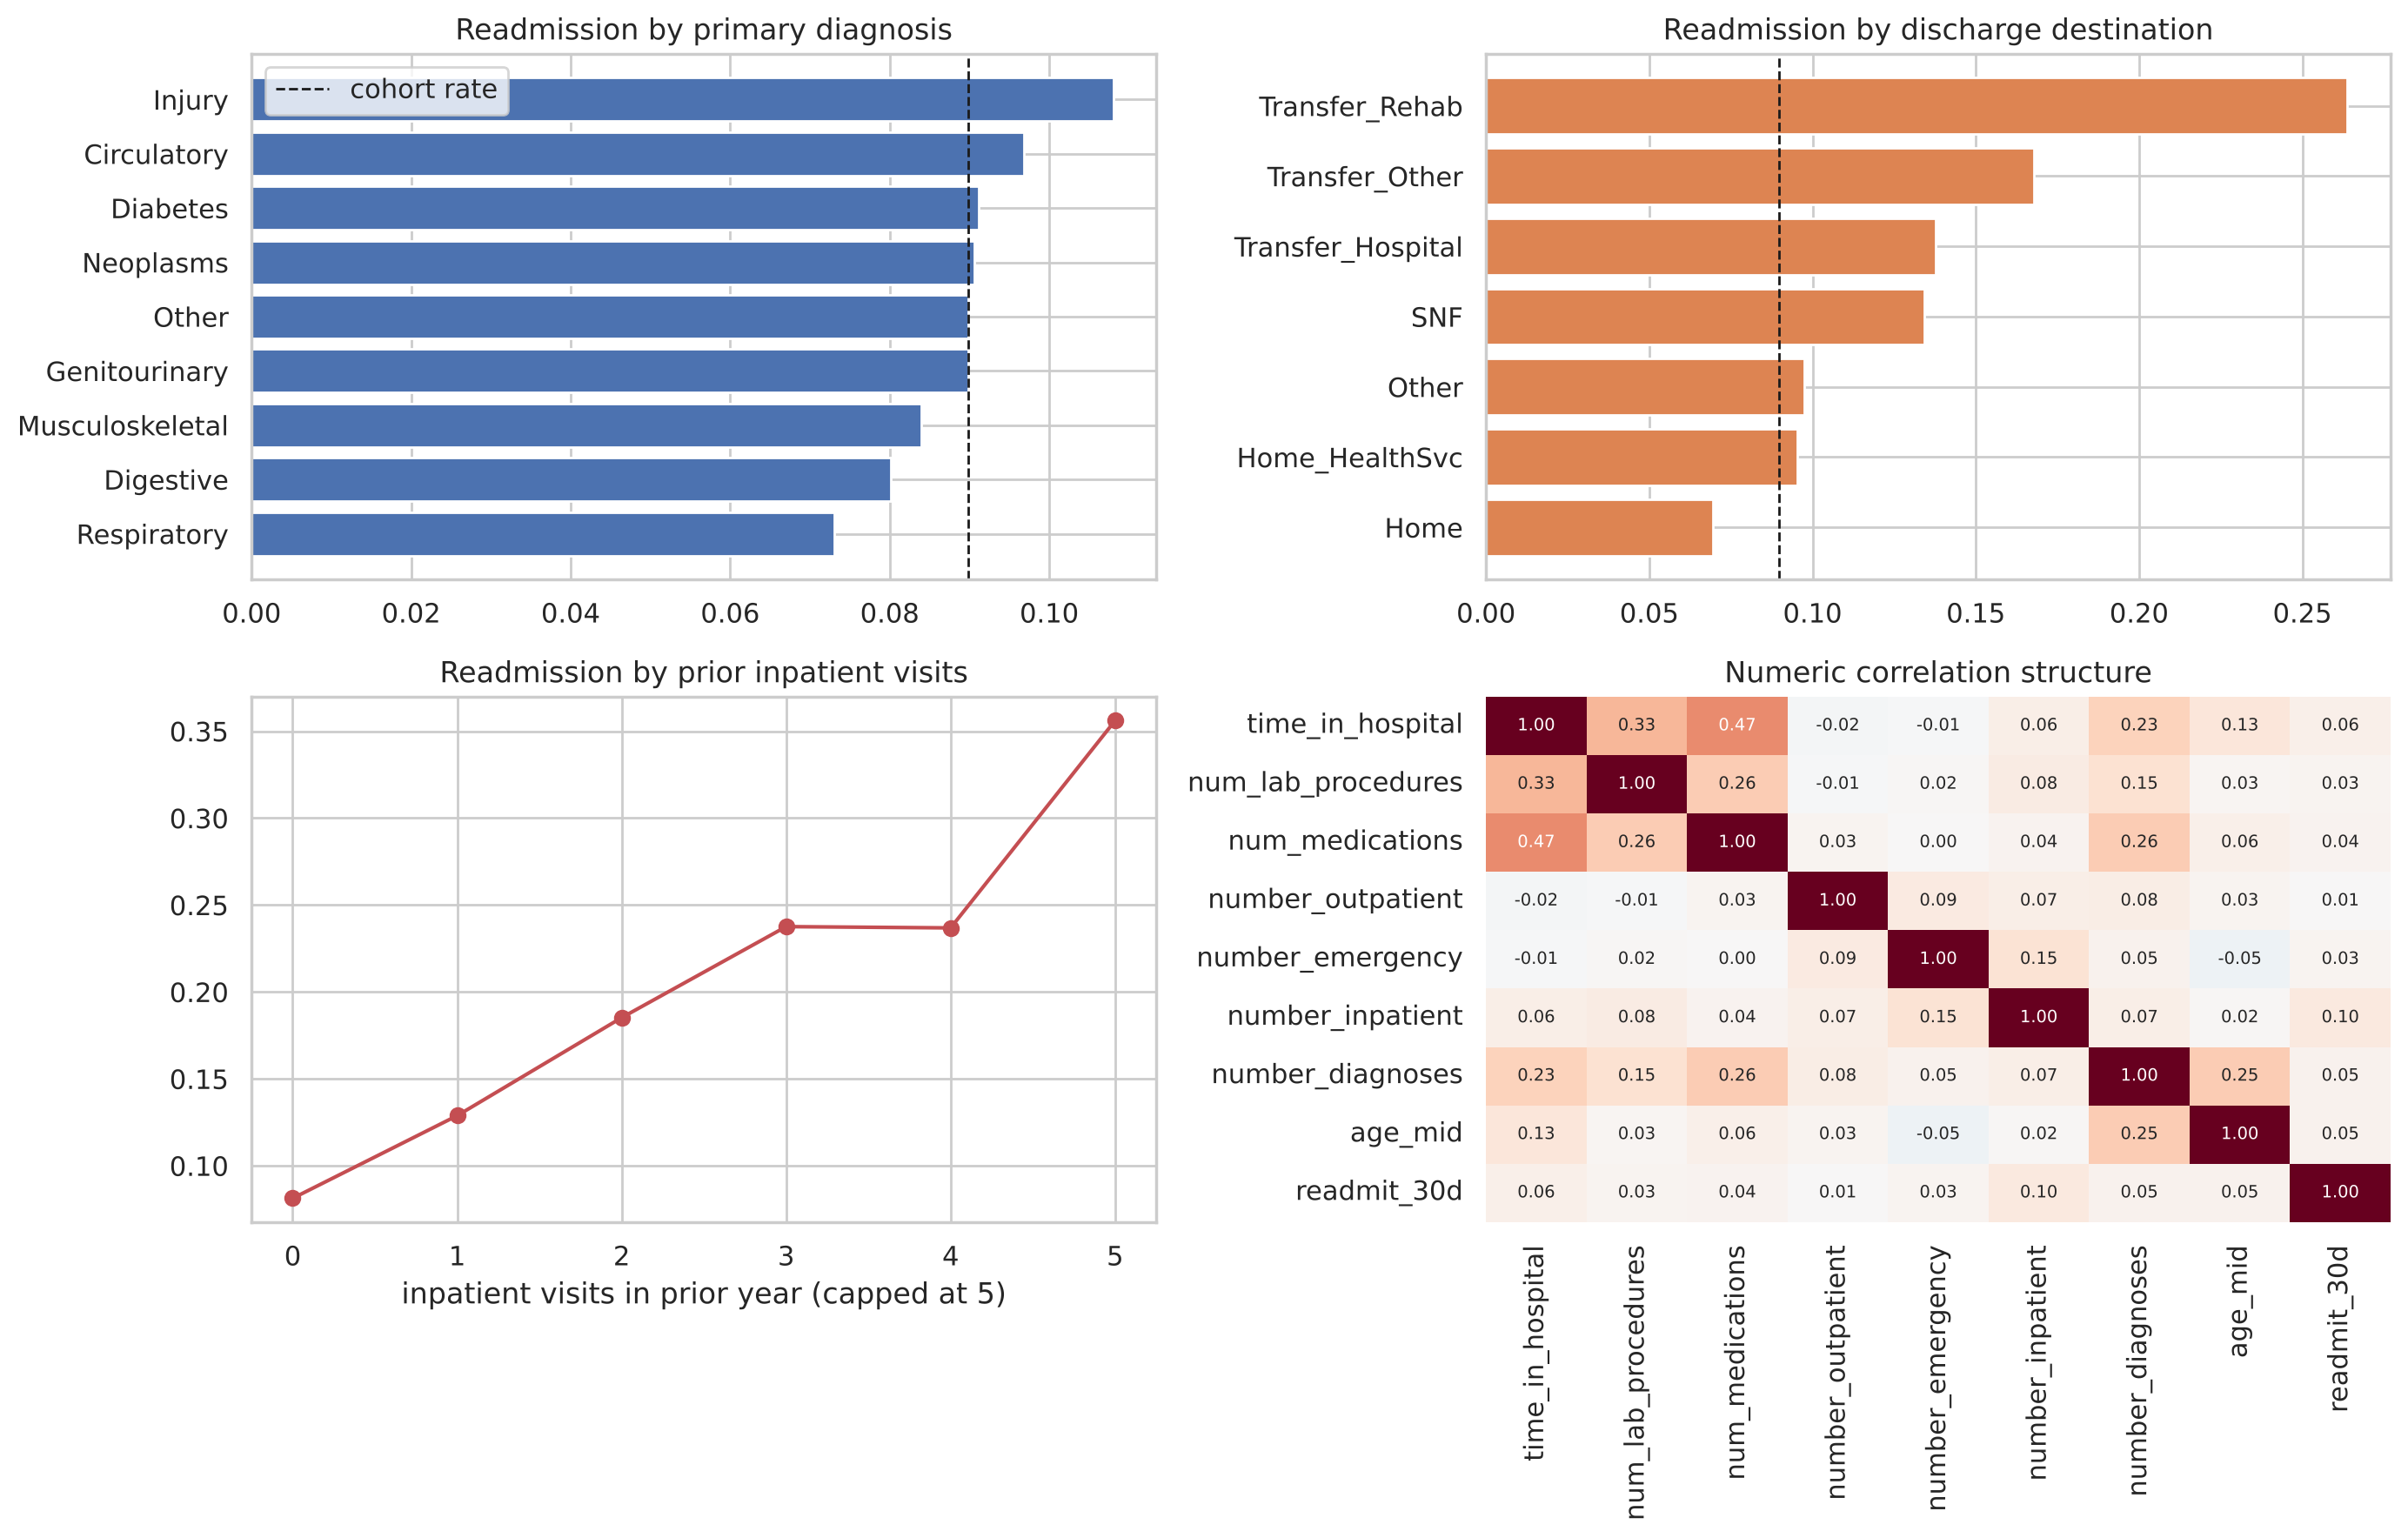

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

rate_diag = (df.groupby('diag_1_grp')['readmit_30d'].agg(['mean', 'size'])
               .query('size >= 300').sort_values('mean'))
ax[0, 0].barh(rate_diag.index, rate_diag['mean'], color='#4C72B0')
ax[0, 0].axvline(COHORT_RATE, ls='--', c='k', lw=1, label='cohort rate')
ax[0, 0].set_title('Readmission by primary diagnosis'); ax[0, 0].legend()

rate_dis = (df.groupby('discharge_grp')['readmit_30d'].agg(['mean', 'size'])
              .query('size >= 300').sort_values('mean'))
ax[0, 1].barh(rate_dis.index, rate_dis['mean'], color='#DD8452')
ax[0, 1].axvline(COHORT_RATE, ls='--', c='k', lw=1)
ax[0, 1].set_title('Readmission by discharge destination')

rate_prior = df.groupby(df['number_inpatient'].clip(upper=5))['readmit_30d'].mean()
ax[1, 0].plot(rate_prior.index, rate_prior.values, 'o-', color='#C44E52')
ax[1, 0].set_title('Readmission by prior inpatient visits')
ax[1, 0].set_xlabel('inpatient visits in prior year (capped at 5)')

num_cols = ['time_in_hospital', 'num_lab_procedures', 'num_medications',
            'number_outpatient', 'number_emergency', 'number_inpatient',
            'number_diagnoses', 'age_mid', 'readmit_30d']
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, ax=ax[1, 1], cbar=False, annot_kws={'size': 7})
ax[1, 1].set_title('Numeric correlation structure')

plt.tight_layout(); plt.show()

---
## 3. Initial Model Development
*Owner: Omkar*

### 3.1 Train/test split — before any transform is fitted

Fitting a scaler or imputer on the full dataset and splitting afterwards leaks test statistics into the training transform. We split first, then fit every transform inside a `Pipeline` so cross-validation refits them per fold. The split is **stratified**, because with this class balance an unstratified split can produce materially different positive rates between train and test.

In [15]:
# two numeric blocks: PLAIN is only scaled; SKEWED is winsorized + log1p inside the
# pipeline (3.2), so its limits are learned from training rows only
NUMERIC_PLAIN = ['time_in_hospital', 'num_procedures', 'number_diagnoses', 'age_mid'] + UNTOUCHED
NUMERIC_SKEWED = SKEWED
NUMERIC = NUMERIC_PLAIN + NUMERIC_SKEWED
print(f'numeric, scaled only        ({len(NUMERIC_PLAIN)}): {NUMERIC_PLAIN}')
print(f'numeric, winsorize + log1p  ({len(NUMERIC_SKEWED)}): {NUMERIC_SKEWED}')

CATEGORICAL = ['race', 'gender', 'admission_type_id', 'admission_source_id',
               'discharge_grp', 'A1Cresult', 'max_glu_serum', 'insulin', 'metformin',
               'change', 'diabetesMed', 'utilization_tier',
               'diag_1_grp', 'diag_2_grp', 'diag_3_grp']

AUDIT_ONLY = [c for c in ['payer_code'] if c in df.columns]   # audited, never predicted

X = df[NUMERIC + CATEGORICAL].copy()

# Missing categoricals become an EXPLICIT 'Unknown' level.
# Written this way on purpose: a bare .astype(str) turns NaN into the literal
# string 'nan' on pandas 2.x (what Colab ships), which then survives imputation
# and shows up as a group called 'nan' in the fairness audit.
for c in CATEGORICAL:
    X[c] = X[c].astype(object).where(X[c].notna(), 'Unknown').astype(str)

assert 'nan' not in set(X['race'].unique()), "literal 'nan' leaked into a category"
print('race levels entering the model:', sorted(X['race'].unique()))

y = df['readmit_30d']
strata = df[AUDIT_ONLY].copy() if AUDIT_ONLY else pd.DataFrame(index=df.index)

X_train, X_test, y_train, y_test, _, strata_test = train_test_split(
    X, y, strata, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

print(f'\ntrain {X_train.shape}   test {X_test.shape}')
print(f'positive rate   train {y_train.mean():.4f}   test {y_test.mean():.4f}')

numeric, scaled only        (5): ['time_in_hospital', 'num_procedures', 'number_diagnoses', 'age_mid', 'num_lab_procedures']
numeric, winsorize + log1p  (6): ['num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'prior_visits', 'meds_per_day']
race levels entering the model: ['AfricanAmerican', 'Asian', 'Caucasian', 'Hispanic', 'Other', 'Unknown']

train (52490, 26)   test (17497, 26)
positive rate   train 0.0898   test 0.0898


#### Why race is given an explicit `Unknown` level rather than mode-imputed

Mode-imputing a protected attribute assigns the majority category to patients whose race was never recorded. That inflates the majority group, erases the missing-data group, and corrupts the fairness audit in Section 4 — the audit would report on a population that does not exist. `Unknown` is kept as a stratum so the audit can ask whether patients with unrecorded race are served as well as everyone else.

### 3.2 Preprocessing pipeline

Every fitted quantity lives inside the pipeline: the scaler's means, the encoder's category list, and the winsorizing limits for the skewed counts. `WinsorLog1p` is a small custom transformer that learns the 1st and 99th percentiles in `fit` and applies clip-then-`log1p` in `transform`, so cross-validation relearns the limits on each training fold and the test set never informs them.

In [16]:
class WinsorLog1p(BaseEstimator, TransformerMixin):
    """Winsorize each column at percentiles learned in fit, then apply log1p."""

    def __init__(self, lower=1, upper=99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_, self.hi_ = np.percentile(X, [self.lower, self.upper], axis=0)
        return self

    def transform(self, X):
        return np.log1p(np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_))

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

skewed_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('winsor_log', WinsorLog1p()),
    ('scale', StandardScaler()),
])

categorical_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=20,
                             sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, NUMERIC_PLAIN),
    ('skew', skewed_pipe, NUMERIC_SKEWED),
    ('cat', categorical_pipe, CATEGORICAL),
])

n_features = preprocessor.fit_transform(X_train).shape[1]
print(f'{len(NUMERIC) + len(CATEGORICAL)} input columns -> {n_features} model features')

if NUMERIC_SKEWED:
    wl = preprocessor.named_transformers_['skew'].named_steps['winsor_log']
    print('\nwinsorizing limits learned from the TRAINING rows only:')
    print(pd.DataFrame({'p1': wl.lo_, 'p99': wl.hi_}, index=NUMERIC_SKEWED).to_string())

26 input columns -> 97 model features

winsorizing limits learned from the TRAINING rows only:
                         p1   p99
num_medications    3.000000  44.0
number_outpatient  0.000000   4.0
number_emergency   0.000000   2.0
number_inpatient   0.000000   3.0
prior_visits       0.000000   6.0
meds_per_day       0.833333  20.0


### 3.3 Baseline models

Two models for contrast, not for a leaderboard. Logistic regression is the interpretable reference; the random forest captures interactions the linear model cannot. Both use balanced class weights so the minority class is not ignored during fitting.

In [17]:
baselines = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest (untuned)': RandomForestClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=20,
        class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE),
}

rows, fitted = {}, {}
for name, clf in baselines.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)]).fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    rows[name] = {'ROC-AUC': roc_auc_score(y_test, proba),
                  'PR-AUC': average_precision_score(y_test, proba),
                  'Accuracy': ((proba >= .5).astype(int) == y_test).mean()}
    fitted[name] = (pipe, proba)

pd.DataFrame(rows).T.round(4)

,ROC-AUC,PR-AUC,Accuracy
Logistic Regression,0.6457,0.1638,0.6571
Random Forest (untuned),0.6507,0.1686,0.7224


### 3.4 Hyperparameter tuning

`scoring='average_precision'`, not `'accuracy'`. Tuning on accuracy against this class balance rewards a model for predicting the majority class everywhere — the exact failure mode we are guarding against. Model selection uses cross-validation on the **training set only** — no test data reaches the search. Two later steps do read the test set and should be named rather than glossed over: the baselines in 3.3 are scored on it, and the capacity threshold in 3.6 is a quantile of test-set scores. In deployment that threshold would be fixed on a separate validation split, so the recall and precision reported at it are mildly optimistic.

In [18]:
param_grid = {
    'clf__n_estimators': [200, 400],
    'clf__max_depth': [8, 12, None],
    'clf__min_samples_leaf': [20],
}

grid = GridSearchCV(
    Pipeline([('prep', preprocessor),
              ('clf', RandomForestClassifier(class_weight='balanced_subsample',
                                             n_jobs=-1, random_state=RANDOM_STATE))]),
    param_grid, cv=3, scoring='average_precision', n_jobs=-1)

grid.fit(X_train, y_train)

print(f'best params    : {grid.best_params_}')
print(f'best CV PR-AUC : {grid.best_score_:.4f}')

best params    : {'clf__max_depth': 12, 'clf__min_samples_leaf': 20, 'clf__n_estimators': 200}
best CV PR-AUC : 0.1672


### 3.5 The tuned model becomes the final model

Everything downstream — threshold selection, interpretability, the fairness audit — uses `final_model`. Tuning a model and then evaluating a different one is a silent and common error; naming the final estimator once makes it impossible.

In [19]:
final_model = grid.best_estimator_
final_proba = final_model.predict_proba(X_test)[:, 1]

rows['Random Forest (TUNED - final)'] = {
    'ROC-AUC': roc_auc_score(y_test, final_proba),
    'PR-AUC': average_precision_score(y_test, final_proba),
    'Accuracy': ((final_proba >= .5).astype(int) == y_test).mean()}

scoreboard = pd.DataFrame(rows).T.round(4)
display(scoreboard)

print(f'Majority-class accuracy (predict nobody readmitted): {1 - COHORT_RATE:.4f}')
print(f'Random-classifier PR-AUC (= cohort positive rate)  : {COHORT_RATE:.4f}')
print()
print('Compare any accuracy figure against the first number, PR-AUC against the second.')

,ROC-AUC,PR-AUC,Accuracy
Logistic Regression,0.6457,0.1638,0.6571
Random Forest (untuned),0.6507,0.1686,0.7224
Random Forest (TUNED - final),0.6497,0.1670,0.7218


Majority-class accuracy (predict nobody readmitted): 0.9102
Random-classifier PR-AUC (= cohort positive rate)  : 0.0898

Compare any accuracy figure against the first number, PR-AUC against the second.


#### Reading the scoreboard

The commentary below is generated from the numbers just computed, so it cannot drift out of step with the table when the notebook is re-run.

In [20]:
win   = scoreboard['PR-AUC'].idxmax()
lr    = scoreboard.loc['Logistic Regression']
tuned = scoreboard.loc['Random Forest (TUNED - final)']
base  = scoreboard.loc['Random Forest (untuned)']
majority_acc = 1 - COHORT_RATE

ratio = scoreboard.loc[win, 'PR-AUC'] / COHORT_RATE
print(f'Best by PR-AUC: {win} at {scoreboard.loc[win, "PR-AUC"]:.4f}, '
      f'{ratio:.2f}x the {COHORT_RATE:.4f} a random ranker would score.')
print('  ->', 'The model carries usable ranking signal.' if ratio >= 1.5
      else 'The signal over a random ranker is weak.')
print()

print(f'Tuning moved the forest\'s PR-AUC from {base["PR-AUC"]:.4f} to {tuned["PR-AUC"]:.4f} '
      f'({tuned["PR-AUC"] - base["PR-AUC"]:+.4f}).')

gap = tuned['PR-AUC'] - lr['PR-AUC']
print(f'Tuned forest vs logistic regression: {gap:+.4f} PR-AUC, '
      f'{tuned["ROC-AUC"] - lr["ROC-AUC"]:+.4f} ROC-AUC.')
if gap <= 0:
    print('  -> The forest does not beat the linear model, so the interpretable model '
          'is the stronger candidate for deployment.')
elif gap < 0.02:
    print('  -> The gap is small, so the interpretable linear model remains a '
          'defensible choice for deployment.')
else:
    print('  -> The gap is large enough to weigh against the loss of direct interpretability.')
print()

below = scoreboard.index[scoreboard['Accuracy'] < majority_acc].tolist()
acc_win = scoreboard['Accuracy'].idxmax()
print(f'Accuracy check: {len(below)} of {len(scoreboard)} models score below the '
      f'{majority_acc:.4f} of a model that flags nobody.')
print(f'  -> Accuracy would pick {acc_win!r}; PR-AUC picks {win!r}.',
      'The two metrics agree here.' if acc_win == win
      else 'The two metrics disagree, which is why accuracy is not the selection metric.')

Best by PR-AUC: Random Forest (untuned) at 0.1686, 1.88x the 0.0898 a random ranker would score.
  -> The model carries usable ranking signal.

Tuning moved the forest's PR-AUC from 0.1686 to 0.1670 (-0.0016).
Tuned forest vs logistic regression: +0.0032 PR-AUC, +0.0040 ROC-AUC.
  -> The gap is small, so the interpretable linear model remains a defensible choice for deployment.

Accuracy check: 3 of 3 models score below the 0.9102 of a model that flags nobody.
  -> Accuracy would pick 'Random Forest (untuned)'; PR-AUC picks 'Random Forest (untuned)'. The two metrics agree here.


### 3.6 Operating point set by the stakeholder's capacity

The default 0.50 threshold is an arbitrary inheritance from balanced-class problems. The team can intensively follow roughly the top 20% of discharges, so the threshold is set at that quantile. `THRESHOLD` is defined once here and reused for the classification report, the confusion matrix and the fairness audit.

In [21]:
CAPACITY = 0.20
THRESHOLD = float(np.quantile(final_proba, 1 - CAPACITY))
flagged = final_proba >= THRESHOLD

tp = int(((y_test == 1) & flagged).sum())
n_pos = int((y_test == 1).sum())

print(f'Operating threshold (top {CAPACITY:.0%} of risk) : {THRESHOLD:.4f}')
print(f'Patients flagged for follow-up              : {flagged.sum():,} of {len(y_test):,}')
print(f'True readmissions captured                  : {tp:,} of {n_pos:,} '
      f'(recall {tp / n_pos:.1%})')
print(f'Precision within flagged group              : {tp / flagged.sum():.1%}')
print(f'Lift over random selection                  : {(tp / flagged.sum()) / COHORT_RATE:.2f}x')

Operating threshold (top 20% of risk) : 0.5229
Patients flagged for follow-up              : 3,500 of 17,497
True readmissions captured                  : 581 of 1,571 (recall 37.0%)
Precision within flagged group              : 16.6%
Lift over random selection                  : 1.85x


Classification report at the operating threshold (0.5229):

                 precision    recall  f1-score   support

 not readmitted       0.93      0.82      0.87     15926
readmitted <30d       0.17      0.37      0.23      1571

       accuracy                           0.78     17497
      macro avg       0.55      0.59      0.55     17497
   weighted avg       0.86      0.78      0.81     17497



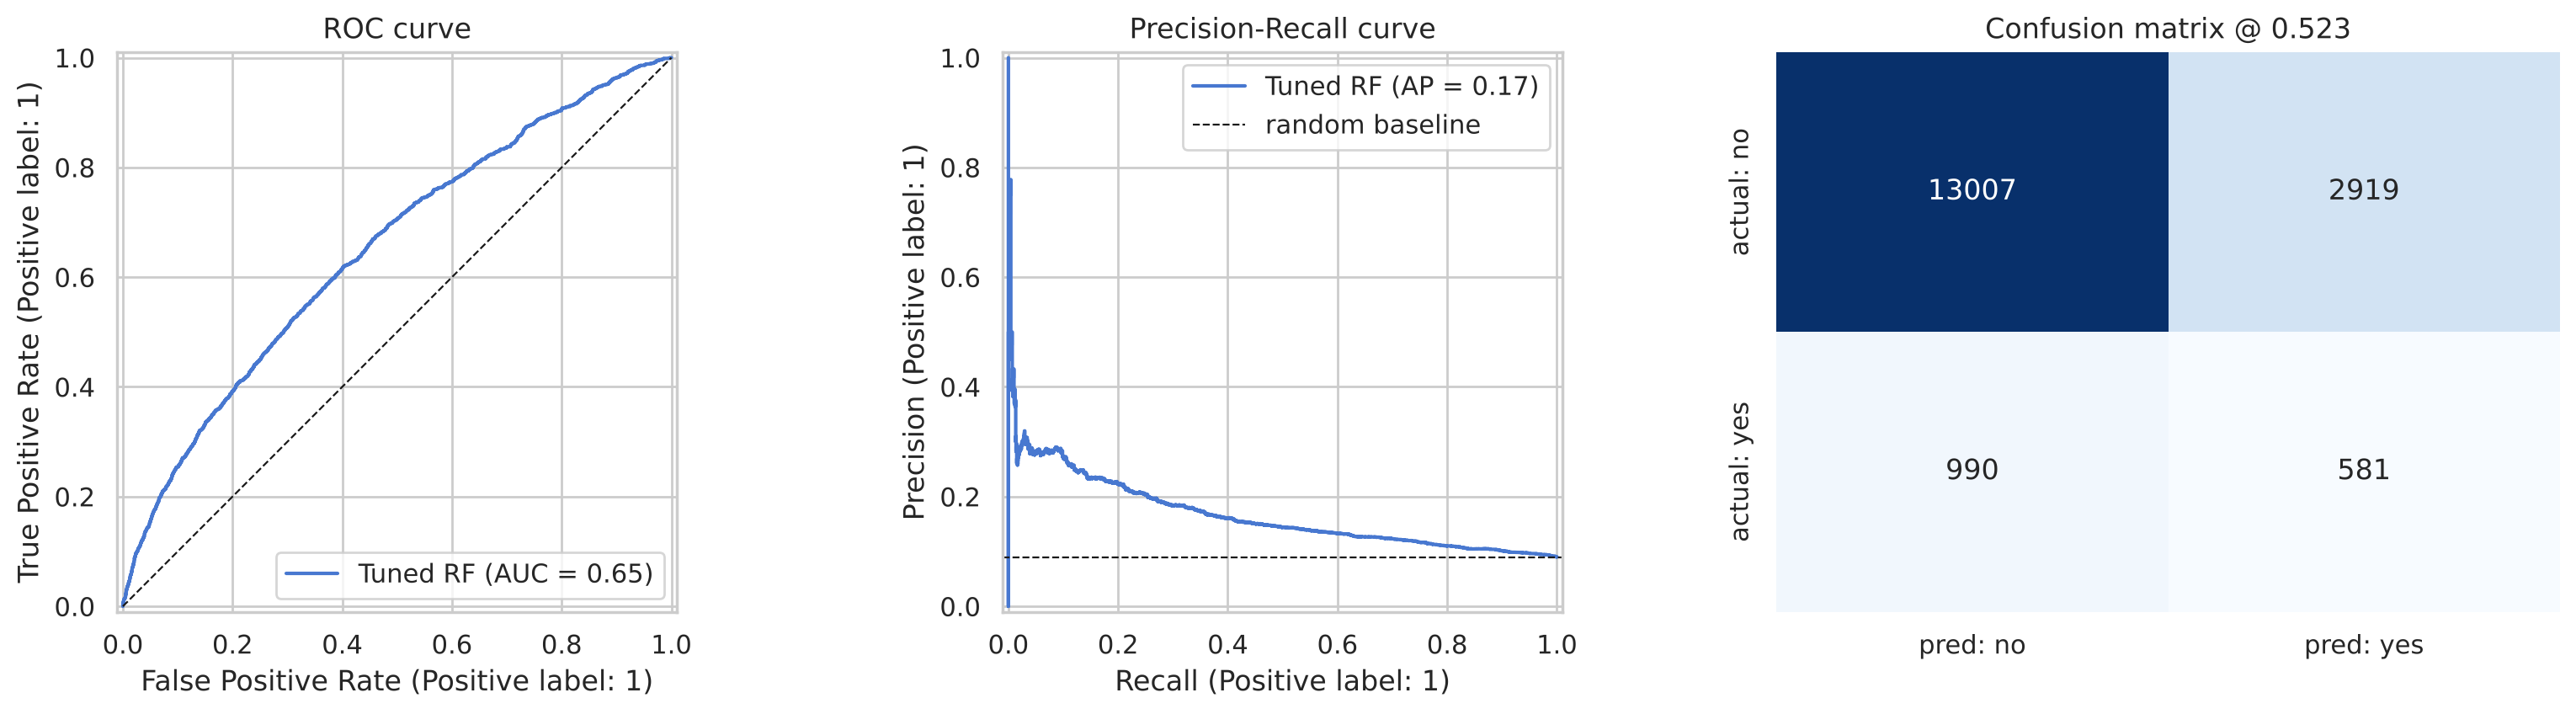

In [22]:
print(f'Classification report at the operating threshold ({THRESHOLD:.4f}):\n')
print(classification_report(y_test, flagged.astype(int),
                            target_names=['not readmitted', 'readmitted <30d']))

cm = confusion_matrix(y_test, flagged.astype(int))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

RocCurveDisplay.from_predictions(y_test, final_proba, ax=ax[0], name='Tuned RF')
ax[0].plot([0, 1], [0, 1], 'k--', lw=.8); ax[0].set_title('ROC curve')

PrecisionRecallDisplay.from_predictions(y_test, final_proba, ax=ax[1], name='Tuned RF')
ax[1].axhline(COHORT_RATE, ls='--', c='k', lw=.8, label='random baseline')
ax[1].set_title('Precision-Recall curve'); ax[1].legend()

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[2], cbar=False,
            xticklabels=['pred: no', 'pred: yes'],
            yticklabels=['actual: no', 'actual: yes'])
ax[2].set_title(f'Confusion matrix @ {THRESHOLD:.3f}')

plt.tight_layout(); plt.show()

### 3.7 Interpretability

Two importance measures are reported together because they answer different questions and need not agree.

`feature_importances_` on a random forest is **impurity-based** (mean decrease in impurity). It is computed on the training data and is known to inflate the apparent importance of continuous and high-cardinality features, because such features offer more split points.

A naive side-by-side of the two would not be a fair comparison: permutation importance scores one value per *original column*, while impurity importance scores one value per *one-hot indicator*, so a categorical variable gets its weight split across many bars. We therefore sum the impurity scores back to their source columns before comparing, and let the cell report how far the two rankings actually agree rather than asserting it in prose.

**Permutation importance** measures the drop in test-set PR-AUC when a column is shuffled. It answers the question a stakeholder actually asks — *does this variable help on data the model has not seen?* — so it is the measure we report. The impurity ranking is shown only for contrast.

97 encoded features aggregated to 26 source columns


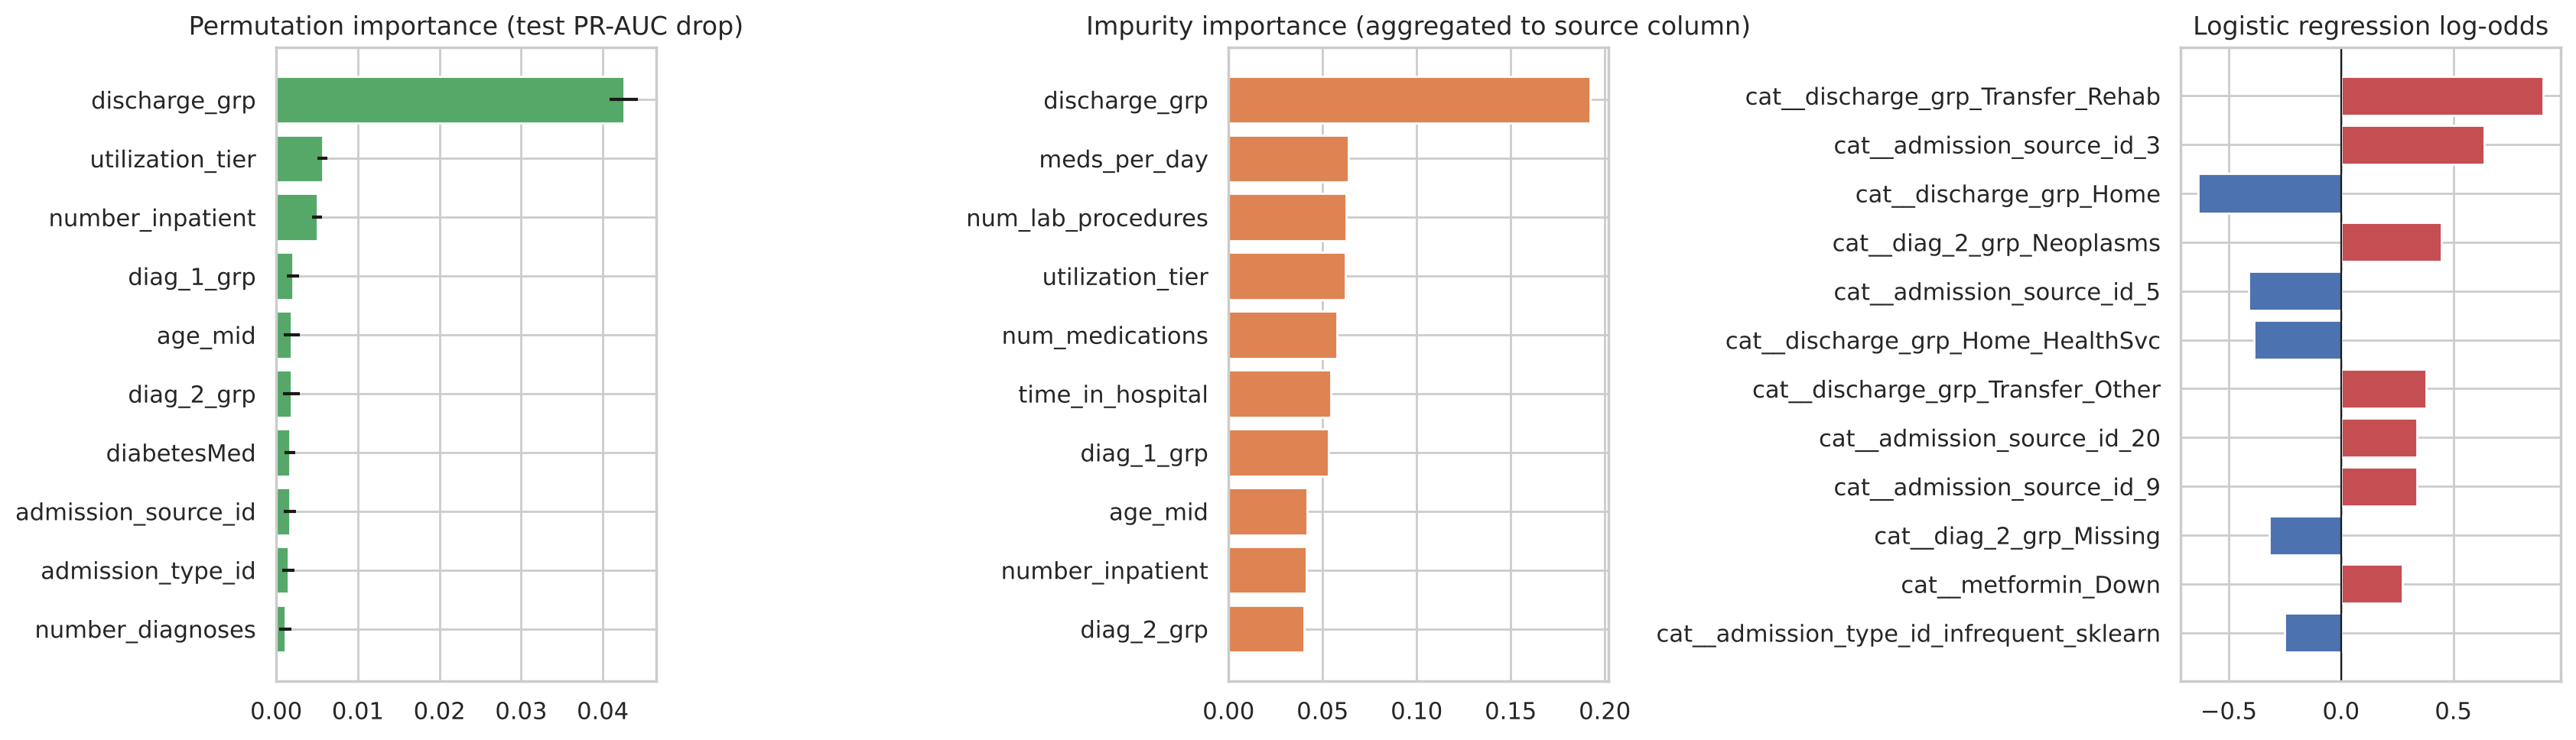

Permutation importance (top 10):
discharge_grp          0.04258
utilization_tier       0.00568
number_inpatient       0.00503
diag_1_grp             0.00203
age_mid                0.00188
diag_2_grp             0.00186
diabetesMed            0.00169
admission_source_id    0.00168
admission_type_id      0.00149
number_diagnoses       0.00112

Top-10 overlap between the two measures: 6 of 10
  permutation only : ['diabetesMed', 'admission_source_id', 'admission_type_id', 'number_diagnoses']
  impurity only    : ['meds_per_day', 'num_lab_procedures', 'num_medications', 'time_in_hospital']
  top feature       : permutation='discharge_grp'  impurity='discharge_grp'  -> agree


In [23]:
perm = permutation_importance(final_model, X_test, y_test, n_repeats=5,
                              scoring='average_precision',
                              random_state=RANDOM_STATE, n_jobs=-1)

perm_s = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
perm_sd = pd.Series(perm.importances_std, index=X_test.columns)

def source_column(fname):
    """Map an encoded feature name back to the original column it came from."""
    bare = fname.split('__', 1)[1] if '__' in fname else fname
    if bare in NUMERIC:
        return bare
    hits = [c for c in CATEGORICAL if bare == c or bare.startswith(c + '_')]
    return max(hits, key=len) if hits else bare


# sum one-hot indicators back to their source column so the two measures are comparable
raw_imp = pd.Series(final_model.named_steps['clf'].feature_importances_,
                    index=final_model.named_steps['prep'].get_feature_names_out())
impurity = raw_imp.groupby(raw_imp.index.map(source_column)).sum().sort_values(ascending=False)
print(f'{len(raw_imp)} encoded features aggregated to {len(impurity)} source columns')

lr_pipe = fitted['Logistic Regression'][0]
coefs = pd.Series(lr_pipe.named_steps['clf'].coef_[0],
                  index=lr_pipe.named_steps['prep'].get_feature_names_out())
top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12)

fig, ax = plt.subplots(1, 3, figsize=(17, 5))

top_perm = perm_s.head(10).iloc[::-1]
ax[0].barh(top_perm.index, top_perm.values,
           xerr=perm_sd[top_perm.index].values, color='#55A868')
ax[0].set_title('Permutation importance (test PR-AUC drop)')

imp10 = impurity.head(10).iloc[::-1]
ax[1].barh(imp10.index, imp10.values, color='#DD8452')
ax[1].set_title('Impurity importance (aggregated to source column)')

ax[2].barh(top_coefs.index, top_coefs.values,
           color=['#C44E52' if v > 0 else '#4C72B0' for v in top_coefs.values])
ax[2].axvline(0, c='k', lw=.8); ax[2].invert_yaxis()
ax[2].set_title('Logistic regression log-odds')

plt.tight_layout(); plt.show()

print('Permutation importance (top 10):')
print(perm_s.head(10).round(5).to_string())

# let the data say whether the two measures agree, rather than asserting it
pt, it = list(perm_s.head(10).index), list(impurity.head(10).index)
shared = set(pt) & set(it)
print(f'\nTop-10 overlap between the two measures: {len(shared)} of 10')
print(f'  permutation only : {[c for c in pt if c not in shared]}')
print(f'  impurity only    : {[c for c in it if c not in shared]}')
print(f'  top feature       : permutation={pt[0]!r}  impurity={it[0]!r}'
      f'  -> {"agree" if pt[0] == it[0] else "DISAGREE"}')

---
## 4. Ethical Considerations
*Owner: Santosh*

### 4.1 Fairness audit at the deployment threshold

The audit runs at `THRESHOLD`, the operating point from Section 3.6 — not at 0.50. Auditing a threshold the system will never use answers a question nobody asked.

The criterion is **equal opportunity**: among patients who genuinely were readmitted, does the model flag them at the same rate across groups? A gap in recall means one group is systematically denied the follow-up resource.

In [24]:
def group_metrics(y_true, y_prob, groups, threshold, min_n=100):
    """Per-group confusion-matrix metrics at a given operating threshold."""
    pred = (y_prob >= threshold).astype(int)
    groups = pd.Series(groups).reset_index(drop=True)
    yt_all = pd.Series(y_true).reset_index(drop=True)
    out = []
    for g in groups.dropna().unique():
        m = (groups == g).to_numpy()
        if m.sum() < min_n:
            continue
        yt, yp = yt_all.to_numpy()[m], pred[m]
        tp = int(((yt == 1) & (yp == 1)).sum()); fn = int(((yt == 1) & (yp == 0)).sum())
        fp = int(((yt == 0) & (yp == 1)).sum()); tn = int(((yt == 0) & (yp == 0)).sum())
        out.append({'group': g, 'n': int(m.sum()), 'positives': tp + fn,
                    'base_rate': yt.mean(),
                    'flagged_rate': yp.mean(),
                    'recall_TPR': tp / (tp + fn) if tp + fn else np.nan,
                    'FPR': fp / (fp + tn) if fp + tn else np.nan,
                    'precision': tp / (tp + fp) if tp + fp else np.nan,
                    'AUC': roc_auc_score(yt, y_prob[m]) if len(np.unique(yt)) > 1 else np.nan})
    return pd.DataFrame(out).set_index('group').sort_values('n', ascending=False).round(3)


print(f'All audits evaluated at THRESHOLD = {THRESHOLD:.4f} (top {CAPACITY:.0%})\n')

print('=== By race ===')
race_audit = group_metrics(y_test, final_proba, X_test['race'], THRESHOLD)
display(race_audit)

print('=== By gender ===')
gender_audit = group_metrics(y_test, final_proba, X_test['gender'], THRESHOLD)
display(gender_audit)

print('=== By age band ===')
age_audit = group_metrics(y_test, final_proba,
                          pd.cut(X_test['age_mid'], [0, 40, 60, 75, 100]).astype(str),
                          THRESHOLD)
display(age_audit)

All audits evaluated at THRESHOLD = 0.5229 (top 20%)

=== By race ===


,n,positives,base_rate,flagged_rate,recall_TPR,FPR,precision,AUC
group,,,,,,,,
Caucasian,13099,1194,0.091,0.217,0.378,0.201,0.159,0.640
AfricanAmerican,3152,287,0.091,0.151,0.334,0.133,0.202,0.669
Unknown,461,31,0.067,0.150,0.355,0.135,0.159,0.728
Hispanic,366,33,0.090,0.172,0.424,0.147,0.222,0.702
Other,296,15,0.051,0.135,0.333,0.125,0.125,0.705
Asian,123,11,0.089,0.098,0.364,0.071,0.333,0.721


=== By gender ===


,n,positives,base_rate,flagged_rate,recall_TPR,FPR,precision,AUC
group,,,,,,,,
Female,9365,826,0.088,0.221,0.390,0.205,0.156,0.653
Male,8132,745,0.092,0.176,0.348,0.159,0.181,0.646


=== By age band ===


,n,positives,base_rate,flagged_rate,recall_TPR,FPR,precision,AUC
group,,,,,,,,
"(60, 75]",8365,813,0.097,0.222,0.390,0.204,0.171,0.635
"(40, 60]",4760,350,0.074,0.100,0.251,0.088,0.185,0.652
"(75, 100]",3269,341,0.104,0.333,0.469,0.317,0.147,0.622
"(0, 40]",1103,67,0.061,0.073,0.239,0.063,0.198,0.708


In [25]:
# payer_code was deliberately excluded from the features - audit by it anyway
payer_audit = None
if AUDIT_ONLY:
    payer = strata_test['payer_code'].fillna('Unknown')
    print('=== By payer code (excluded as a feature, audited as a stratum) ===')
    payer_audit = group_metrics(y_test, final_proba, payer, THRESHOLD)
    display(payer_audit)

=== By payer code (excluded as a feature, audited as a stratum) ===


,n,positives,base_rate,flagged_rate,recall_TPR,FPR,precision,AUC
group,,,,,,,,
Unknown,7692,762,0.099,0.205,0.386,0.185,0.186,0.653
MC,4912,485,0.099,0.263,0.379,0.251,0.142,0.603
HM,1021,59,0.058,0.119,0.288,0.109,0.139,0.692
BC,824,36,0.044,0.074,0.250,0.066,0.148,0.665
SP,816,63,0.077,0.129,0.317,0.113,0.190,0.644
MD,527,38,0.072,0.182,0.263,0.176,0.104,0.639
CP,484,36,0.074,0.105,0.250,0.094,0.176,0.622
UN,464,33,0.071,0.140,0.364,0.123,0.185,0.681
CM,316,28,0.089,0.250,0.607,0.215,0.215,0.776


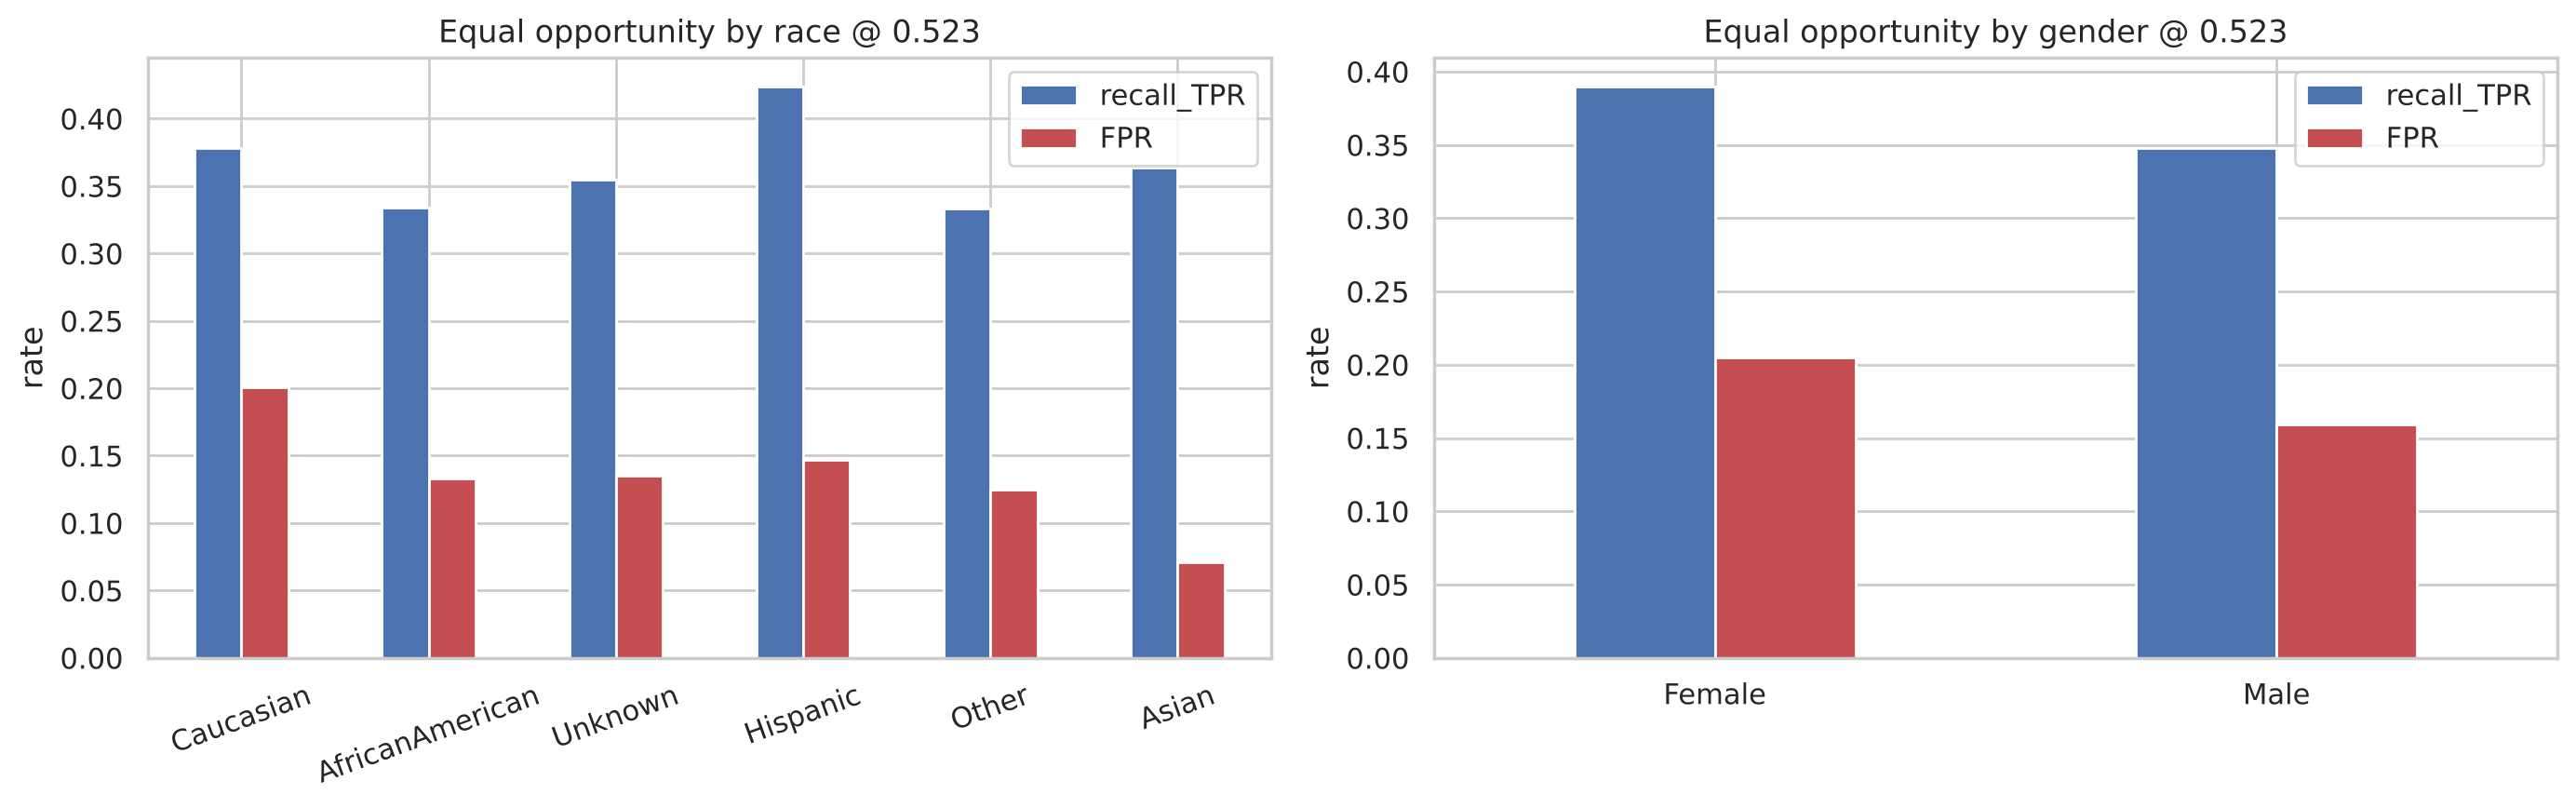

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

race_audit[['recall_TPR', 'FPR']].plot(kind='bar', ax=ax[0], rot=20,
                                       color=['#4C72B0', '#C44E52'])
ax[0].set_title(f'Equal opportunity by race @ {THRESHOLD:.3f}')
ax[0].set_ylabel('rate'); ax[0].set_xlabel('')

gender_audit[['recall_TPR', 'FPR']].plot(kind='bar', ax=ax[1], rot=0,
                                         color=['#4C72B0', '#C44E52'])
ax[1].set_title(f'Equal opportunity by gender @ {THRESHOLD:.3f}')
ax[1].set_ylabel('rate'); ax[1].set_xlabel('')

plt.tight_layout(); plt.show()

#### Audit summary

Recall is a ratio over actual readmissions, so it is only estimable for a group that contains enough of them. The cell below reports each spread twice — across all groups, and restricted to groups with at least 30 actual readmissions in the test set — and applies a 0.05 review trigger to the restricted figure. The sentences are generated from the audit tables, so they always describe the run above.

In [27]:
MIN_POSITIVES = 30
REVIEW_TRIGGER = 0.05

overall_recall = flagged[(y_test == 1).to_numpy()].mean()
overall_precision = (y_test.to_numpy()[flagged] == 1).mean()

print(f'Overall, at the operating threshold: recall {overall_recall:.3f}, '
      f'precision {overall_precision:.3f}.\n')

audits = {'race': race_audit, 'gender': gender_audit, 'age band': age_audit}
if payer_audit is not None:
    audits['payer code'] = payer_audit

for name, audit in audits.items():
    ok = audit[audit['positives'] >= MIN_POSITIVES]
    small = [str(g) for g in audit.index if g not in ok.index]
    all_spread = audit['recall_TPR'].max() - audit['recall_TPR'].min()
    print(f'By {name}:')
    if len(ok) > 1:
        lo_g, hi_g = ok['recall_TPR'].idxmin(), ok['recall_TPR'].idxmax()
        spread = ok['recall_TPR'].max() - ok['recall_TPR'].min()
        print(f'  recall runs from {ok.loc[lo_g, "recall_TPR"]:.3f} ({lo_g}) to '
              f'{ok.loc[hi_g, "recall_TPR"]:.3f} ({hi_g}) across the {len(ok)} estimable groups: '
              f'spread {spread:.3f}.')
        print('  -> ABOVE the review trigger: investigate before deployment.'
              if spread > REVIEW_TRIGGER else '  -> within the review trigger.')
    else:
        print('  too few groups with enough readmissions to compute a meaningful spread.')
    if small:
        print(f'  spread over ALL groups is {all_spread:.3f}, but {small} have fewer than '
              f'{MIN_POSITIVES} readmissions, so that figure is partly noise.')
    print()

print(f'Error profile: of every 10 patients flagged, about {round((1 - overall_precision) * 10)} '
      f'are not readmitted within 30 days (precision {overall_precision:.1%}).')

Overall, at the operating threshold: recall 0.370, precision 0.166.

By race:
  recall runs from 0.334 (AfricanAmerican) to 0.424 (Hispanic) across the 4 estimable groups: spread 0.090.
  -> ABOVE the review trigger: investigate before deployment.
  spread over ALL groups is 0.091, but ['Other', 'Asian'] have fewer than 30 readmissions, so that figure is partly noise.

By gender:
  recall runs from 0.348 (Male) to 0.390 (Female) across the 2 estimable groups: spread 0.042.
  -> within the review trigger.

By age band:
  recall runs from 0.239 ((0, 40]) to 0.469 ((75, 100]) across the 4 estimable groups: spread 0.230.
  -> ABOVE the review trigger: investigate before deployment.

By payer code:
  recall runs from 0.250 (BC) to 0.386 (Unknown) across the 8 estimable groups: spread 0.136.
  -> ABOVE the review trigger: investigate before deployment.
  spread over ALL groups is 0.516, but ['CM', 'OG', 'PO'] have fewer than 30 readmissions, so that figure is partly noise.

Error profile: of

### 4.2 Reflection

**What potential biases exist in the dataset?**

- *Measurement bias.* `race` is recorded by hospital staff, not self-reported, and is missing for a small share of encounters — retained here as an explicit `Unknown` stratum rather than imputed away. `medical_specialty` is roughly half missing, and that missingness is unlikely to be random: it plausibly tracks hospital size and documentation practice, which in turn track patient population.
- *Label bias.* The target records readmission **to the same system**. A patient readmitted elsewhere is silently labelled negative. If continuity of care varies by insurance or geography, this under-counts readmissions non-uniformly across groups — which is precisely why Section 4.1 audits by payer code.
- *Historical bias.* The data covers 1999–2008, a period with materially different diabetes management guidelines. A model trained on it learns the practice of that era, including its inequities.

**How would the model perform across different demographic groups?**

Measured in 4.1 rather than asserted. The audit summary at the end of 4.1 states, for race, gender, age band and payer code, the lowest and highest group recall and whether the spread between them crosses the 0.05 review trigger.

Three caveats bound how far those numbers can be trusted. First, **recall is a ratio over actual readmissions, so a group's recall is only estimable if that group contains enough of them.** The smaller race categories and the `Unknown` stratum hold few readmissions in the test set, which makes their recall swing on one or two patients. The summary therefore reports each spread twice: across all groups, and restricted to groups with at least 30 actual readmissions. A headline spread above the trigger is evidence of bias **only** if it survives that restriction, and even then it is a prompt to look rather than a finding: with 30 readmissions the standard error of a recall near 0.4 is about 0.09. Second, a gap has to be read against what drives it. Age is itself a model input and older patients are readmitted more often, so higher flag rates and recall in the older bands are expected behaviour; a gap by race or payer code has no such justification and is the kind that would block deployment. Third, equal recall does not guarantee equal benefit if the downstream intervention is itself unequally effective across groups.

**Is the model interpretable and fair?**

Partially, and the limits are worth stating plainly. Logistic regression coefficients are directly readable. The random forest is not: permutation importance tells us *which* variables matter in aggregate, but not *why* a specific patient received a specific score. For a deployed clinical tool this gap matters — a care coordinator who cannot explain why a patient was flagged cannot defend the decision to the patient or to a reviewer.

Three transparency commitments follow. Every score surfaced to a clinician carries its top contributing factors. The cohort definition, the operating threshold and the fairness audit are published alongside the model rather than held internally. And the model is documented as a *triage aid* with a stated error profile: most patients the model flags are not in fact readmitted, and the audit summary in 4.1 prints the exact share from the precision at the operating threshold, so that no user mistakes a ranking for a prediction about an individual.

**Is user data being protected?**

The UCI release is de-identified under HIPAA Safe Harbor: no names, addresses, or dates finer than a year, ages in decade bands. Two residual risks remain. Re-identification is conceivable by linking quasi-identifiers (age band, race, gender, admission pattern) against an external source. And `patient_nbr` is a persistent pseudonym, so longitudinal linkage within the dataset is possible — which is why the deduplication step matters for privacy as well as for methodology.

**Deployment constraints.** The model produces a ranked worklist for a care coordinator and never withholds care. Group-level performance is re-audited on every refresh, and the model is retired if recall spread across protected groups exceeds a pre-registered bound.

---
## 5. Methodological deviations from the project hints
*Owner: Santosh*

The guidance in *Hints and Tips for Success* is deliberately dataset-agnostic. Five of its default recipes are harmful on this dataset. We document the substitutions rather than departing from them silently.

| Hints guidance | Problem here | Substitution |
|---|---|---|
| `df.fillna(method='ffill')` | Forward-fill propagates one patient's race or diagnosis into an unrelated patient's record. `method=` is also removed in pandas 3.x. | Column-specific handling: categoricals get an explicit `Unknown` level in 3.1, numerics have no gaps after the cohort filters. The pipeline imputers in 3.2 are therefore safety nets against unseen data, not steps that do work on this cohort. |
| `df.drop_duplicates()` | Removes exact duplicate rows, of which there are none — `encounter_id` is unique. The real leak is duplicate *patients*. | `drop_duplicates('patient_nbr')` |
| `scaler.fit_transform(df)` then split | Fits the scaler on test data — leakage | Split first; scaling and the winsorizing limits inside a `Pipeline`, refit per fold |
| `GridSearchCV(scoring='accuracy')` | With this class balance, accuracy is maximised by predicting nobody is readmitted | `scoring='average_precision'` |
| `pd.get_dummies(df, drop_first=True)` | Would one-hot ~700 ICD-9 codes per diagnosis column | Clinical grouping, then `OneHotEncoder(min_frequency=20)` |

---
## 6. Summary and next steps
*Owner: Santosh*

**What preprocessing bought us.** The cohort filters removed encounters whose outcome was impossible and eliminated patient-level leakage — which also moved the positive rate, so every class-balance statement in this notebook refers to the cohort rate computed in 2.4, not the raw rate. ICD-9 grouping turned roughly 2,100 unusable sparse indicators into the compact set counted in 2.5. None of these steps would have raised an error if skipped.

**Where the initial model stands.** Discrimination is modest, consistent with the published literature: 30-day readmission is substantially driven by social and post-discharge factors — housing stability, caregiver support, medication affordability, outpatient access — that an inpatient encounter record does not observe. The model is nonetheless useful as a triage ranker, delivering measurable lift over random selection at the team's actual capacity.

**Next steps for Deliverable 3.**

1. Gradient boosting (XGBoost / LightGBM) with early stopping as a stronger tabular baseline.
2. Calibration assessment — a coordinator reading "38% risk" needs that to mean something. `CalibratedClassifierCV` plus a reliability curve.
3. Cost-sensitive threshold optimisation using the team's real cost ratio rather than a capacity proxy.
4. Grouped cross-validation by hospital, to estimate transfer to an unseen site.
5. SHAP values for per-patient explanations, closing the transparency gap named in 4.2.

---
## 7. Team Collaboration Process
*Owner: Santosh*

### 7.1 Roles and ownership

| Member | Sections owned | Contribution to Deliverable 2 |
|---|---|---|
| Chinmayee | 1–2 | Problem framing; parsing decisions; the three cohort filters and their audit trail; ICD-9 and discharge grouping; derived utilisation features; exploratory figures |
| Omkar | 3 | Stratified split design; `ColumnTransformer` pipeline; baseline models; grid search on average precision; capacity-based threshold; permutation importance |
| Santosh | 4–7 | Fairness audit at the operating threshold; ethics and transparency reflection; deviations table; summary; this section |

Each member reviews one other's work: Chinmayee reviews Omkar's, Omkar reviews Santosh's, Santosh reviews Chinmayee's. No section is merged on its author's approval alone.

### 7.2 Version control and environment

One GitHub repository ([omkar1117/uc-ind-rp2-grp-5](https://github.com/omkar1117/uc-ind-rp2-grp-5)), created by Omkar, with Chinmayee and Santosh added as collaborators. The notebook is the single source of truth; intermediate CSVs are regenerated rather than committed, so the pipeline is reproducible from the raw UCI archive alone. `RANDOM_STATE = 42` is fixed throughout, so re-running the notebook in the same environment reproduces identical splits and metrics.

The notebook is developed in a shared [Colab notebook](https://colab.research.google.com/drive/1eYXfmnfr8qVV2nsrU0fsjE2HV467Lqp9) and saved to the repository via **File → Save a copy in GitHub**, so the repository holds the version of record. Commits are one-per-fix where practical, so the history is itself the evidence of who did what.

### 7.3 Sequential, not parallel

Notebooks merge badly: two people editing the same `.ipynb` produce conflicts in cell metadata that are painful to resolve by hand. The work is also genuinely sequential — Chinmayee's cohort fixes change the data Omkar's models consume, and Omkar's model outputs are the input to Santosh's audit.

| Order | Owner | Hands off |
|---|---|---|
| 1 | Chinmayee | Cohort row counts and the post-filter positive rate |
| 2 | Omkar | `final_model`, `THRESHOLD`, and the metrics table |
| 3 | Santosh | Audit tables and the completed written report |

On completing a stage, its owner records what changed and the figures the next owner needs, so the handoff is written down rather than carried in conversation.

### 7.4 Design decisions and their rationale

Four choices shape every result in this notebook. Each was a decision the team had to make explicitly, because the obvious default would have produced a worse analysis:

1. **Treating `>30` as a negative.** The multi-class alternative was set aside because both the CMS penalty window and the team's intervention window are 30 days, so a readmission at 45 days is outside the problem as framed.
2. **Removing repeat encounters**, discarding a substantial share of rows. The smaller cohort is preferred because retaining it produces a leaked, unusable validation estimate — a worse outcome than less data.
3. **Excluding `payer_code` as a predictor while auditing by it.** It survived the missingness rule, so using it was available. Insurance status is an ability-to-pay proxy, and encoding it into a clinical triage score is not defensible; checking whether the model underserves self-pay patients is.
4. **Giving missing race an explicit `Unknown` level rather than mode-imputing it.** Imputation would have assigned the majority race to patients whose race was never recorded, producing a fairness audit on a population that does not exist.

---

### References

Clore, J., Cios, K., DeShazo, J., & Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999-2008* \[Dataset\]. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J

Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L., Ventura, S., Cios, K. J., & Clore, J. N. (2014). Impact of HbA1c measurement on hospital readmission rates: Analysis of 70,000 clinical database patient records. *BioMed Research International*, 2014, Article 781670. https://doi.org/10.1155/2014/781670